# LungCT DirectCP 4-Stage Mid-Ratio Pareto Extension

This notebook combines the prior all-10 LungCT Pareto rows, new DirectCP 4-stage mid-ratio rows, and validated pTVReg reference fields. It displays the screening table and saves the requested Pareto figures.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import pandas as pd
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / 'scripts').exists() and REPO_ROOT.parent != REPO_ROOT:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.reports.lungct_midratio_pareto_extension import (
    DEFAULT_OUTPUT_ROOT,
    METHOD_FDBE,
    METHOD_IDIR,
    METHOD_PTVREG,
    METHOD_PTV_DIRECTCP,
    build_review_tables,
    save_and_plot_review,
)

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)
OUTPUT_ROOT = DEFAULT_OUTPUT_ROOT
print(f'Repo root: {REPO_ROOT}')
print(f'Output root: {OUTPUT_ROOT}')

Repo root: /homebase/code_sync/inrorspline
Output root: /homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension


## Editable Exclusion Controls

Edit these dictionaries to exclude points by ratio-to-anchor weight or exact regularization weight. pTVReg is always retained as the reference point.

In [2]:
EXCLUDE_BY_RATIO = {
    METHOD_IDIR: [],
    METHOD_PTV_DIRECTCP: [0.01, 10.0, 100.0],
    METHOD_FDBE: [0.0, 0.001, 0.01],
}

EXCLUDE_BY_WEIGHT = {
    METHOD_IDIR: [],
    METHOD_PTV_DIRECTCP: [],
    METHOD_FDBE: [],
}

print('EXCLUDE_BY_RATIO =', EXCLUDE_BY_RATIO)
print('EXCLUDE_BY_WEIGHT =', EXCLUDE_BY_WEIGHT)

EXCLUDE_BY_RATIO = {'idir_be_default_lungmask': [], 'direct_cp_32_16_8_4_ptv_lcc_isotv': [0.01, 10.0, 100.0], 'direct_cp_32_16_8_4_global_ncc_fd_be': [0.0, 0.001, 0.01]}
EXCLUDE_BY_WEIGHT = {'idir_be_default_lungmask': [], 'direct_cp_32_16_8_4_ptv_lcc_isotv': [], 'direct_cp_32_16_8_4_global_ncc_fd_be': []}


## Load Rows, Validate pTVReg, And Save Tables

In [3]:
tables = build_review_tables()
existing_df = tables['existing_df']
extension_df = tables['extension_df']
ptvreg_df = tables['ptvreg_df']
case_df = tables['case_df']
mean_df = tables['mean_df']
table_df = tables['table_df']
completion_errors = tables['completion_errors']

print(f'Existing trained-method case rows: {len(existing_df)}')
print(f'New extension case rows: {len(extension_df)}')
print(f'pTVReg case rows: {len(ptvreg_df)}')
print(f'Combined case rows: {len(case_df)}')
print(f'Combined mean rows: {len(mean_df)}')
if completion_errors:
    raise RuntimeError('Extension completion errors: ' + '; '.join(completion_errors))

display(Markdown('### Extension rows'))
display(extension_df[['method_label', 'case_id', 'reg_value', 'ratio_to_best_tre_weight' if 'ratio_to_best_tre_weight' in extension_df.columns else 'reg_sort', 'original_snap_tre_mean_mm', 'fg_logj_std']])

display(Markdown('### pTVReg field validation'))
display(ptvreg_df[['case_id', 'source_saved_tre_phys_mean_mm', 'source_recomputed_snap_tre_mean_mm', 'source_tre_validation_abs_err', 'source_saved_trestd_case_mm', 'source_recomputed_snap_tre_std_mm', 'source_trestd_validation_abs_err', 'source_disp_h5py_shape']])

display(Markdown('### Screening table'))
display(table_df)

Existing trained-method case rows: 160
New extension case rows: 60
pTVReg case rows: 10
Combined case rows: 230
Combined mean rows: 23


### Extension rows

,method_label,case_id,reg_value,reg_sort,original_snap_tre_mean_mm,fg_logj_std
0,DirectCP 4stage global-NCC+FD-BE,1,3000.000,3000.0,0.832646,0.149136
1,DirectCP 4stage global-NCC+FD-BE,1,30000.000,30000.0,0.745736,0.086489
2,DirectCP 4stage global-NCC+FD-BE,2,3000.000,3000.0,0.812970,0.144435
3,DirectCP 4stage global-NCC+FD-BE,2,30000.000,30000.0,0.729139,0.081650
4,DirectCP 4stage global-NCC+FD-BE,3,3000.000,3000.0,0.942144,0.168790
5,DirectCP 4stage global-NCC+FD-BE,3,30000.000,30000.0,0.851537,0.101320
6,DirectCP 4stage global-NCC+FD-BE,4,3000.000,3000.0,1.317446,0.292052
7,DirectCP 4stage global-NCC+FD-BE,4,30000.000,30000.0,1.283522,0.190157
8,DirectCP 4stage global-NCC+FD-BE,5,3000.000,3000.0,1.109362,0.222923
9,DirectCP 4stage global-NCC+FD-BE,5,30000.000,30000.0,1.168528,0.141260


### pTVReg field validation

,case_id,source_saved_tre_phys_mean_mm,source_recomputed_snap_tre_mean_mm,source_tre_validation_abs_err,source_saved_trestd_case_mm,source_recomputed_snap_tre_std_mm,source_trestd_validation_abs_err,source_disp_h5py_shape
0,1,0.767141,0.767141,4.440892e-16,0.891749,0.891749,3.330669e-16,"(3, 94, 256, 256)"
1,2,0.750864,0.750864,2.220446e-16,0.898982,0.898982,2.220446e-16,"(3, 112, 256, 256)"
2,3,0.927378,0.927378,2.220446e-16,1.072600,1.072600,0.000000e+00,"(3, 104, 256, 256)"
3,4,1.265704,1.265704,2.220446e-16,1.259225,1.259225,6.661338e-16,"(3, 99, 256, 256)"
4,5,1.077725,1.077725,2.220446e-16,1.417158,1.417158,2.220446e-16,"(3, 106, 256, 256)"
5,6,0.831637,0.831637,3.330669e-16,0.924874,0.924874,0.000000e+00,"(3, 128, 512, 512)"
6,7,0.806061,0.806061,4.440892e-16,0.913381,0.913381,0.000000e+00,"(3, 136, 512, 512)"
7,8,1.014220,1.014220,2.220446e-16,1.292223,1.292223,6.661338e-16,"(3, 128, 512, 512)"
8,9,0.909508,0.909508,5.551115e-16,0.954036,0.954036,3.330669e-16,"(3, 128, 512, 512)"
9,10,0.840979,0.840979,4.440892e-16,0.969514,0.969514,0.000000e+00,"(3, 120, 512, 512)"


### Screening table

,Method,Weight,Ratio,Cases,Original Snap TRE,Original Sub TRE,FG stdLogJ,FG J<=0 %,FG BE,FG diffusion
0,IDIR BE,0.1000,0.010,10,1.317 +/- 0.656,1.408 +/- 0.634,0.3225 +/- 0.1128,0.2938 +/- 0.4034,0.007477 +/- 0.004523,0.023005 +/- 0.012893
1,IDIR BE,1.0000,0.100,10,1.046 +/- 0.200,1.159 +/- 0.166,0.2155 +/- 0.0553,0.0226 +/- 0.0451,0.002427 +/- 0.001137,0.012305 +/- 0.004662
2,IDIR BE,3.0000,0.300,10,1.006 +/- 0.171,1.129 +/- 0.131,0.1752 +/- 0.0427,0.0089 +/- 0.0250,0.001202 +/- 0.000479,0.009198 +/- 0.003460
3,IDIR BE,10.0000,1.000,10,1.017 +/- 0.176,1.133 +/- 0.137,0.1429 +/- 0.0348,2.47e-05 +/- 7.41e-05,0.000535 +/- 0.000181,0.007218 +/- 0.002864
4,IDIR BE,30.0000,3.000,10,1.037 +/- 0.180,1.154 +/- 0.143,0.1213 +/- 0.0297,0.0000 +/- 0.0000,0.000259 +/- 0.000081,0.006062 +/- 0.002517
5,IDIR BE,100.0000,10.000,10,1.085 +/- 0.212,1.196 +/- 0.163,0.1042 +/- 0.0269,0.0000 +/- 0.0000,0.000115 +/- 0.000036,0.005160 +/- 0.002281
6,IDIR BE,1000.0000,100.000,10,1.257 +/- 0.269,1.333 +/- 0.213,0.0789 +/- 0.0217,0.0000 +/- 0.0000,0.000020 +/- 0.000007,0.003827 +/- 0.001935
7,DirectCP 4stage pTV-LCC+isoTV,0.0011,0.010,10,1.320 +/- 0.713,1.393 +/- 0.704,0.6613 +/- 0.1110,2.6170 +/- 1.5585,0.132987 +/- 0.040223,0.098929 +/- 0.036288
8,DirectCP 4stage pTV-LCC+isoTV,0.0110,0.100,10,1.022 +/- 0.206,1.121 +/- 0.169,0.3974 +/- 0.0895,0.4137 +/- 0.3386,0.031837 +/- 0.010742,0.036033 +/- 0.012335
9,DirectCP 4stage pTV-LCC+isoTV,0.0330,0.300,10,0.938 +/- 0.147,1.053 +/- 0.128,0.2680 +/- 0.0662,0.0731 +/- 0.0712,0.009962 +/- 0.003724,0.018350 +/- 0.006708


## Pareto Figures

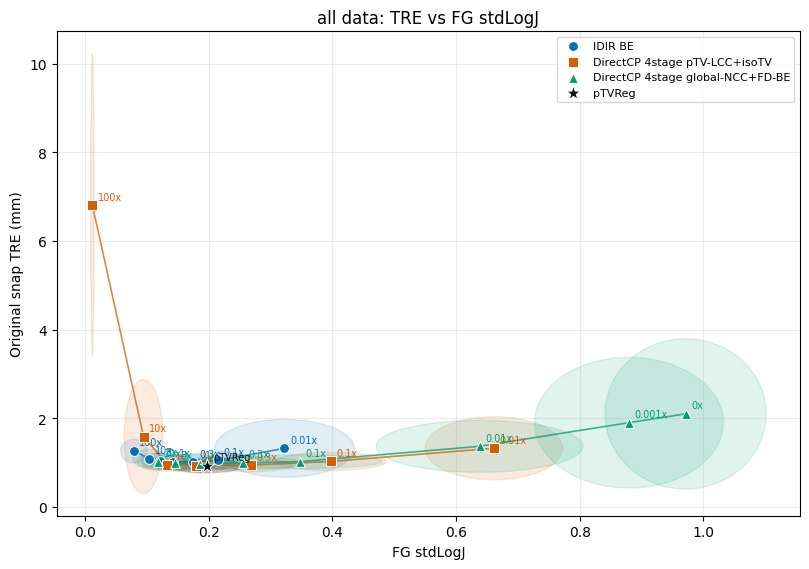

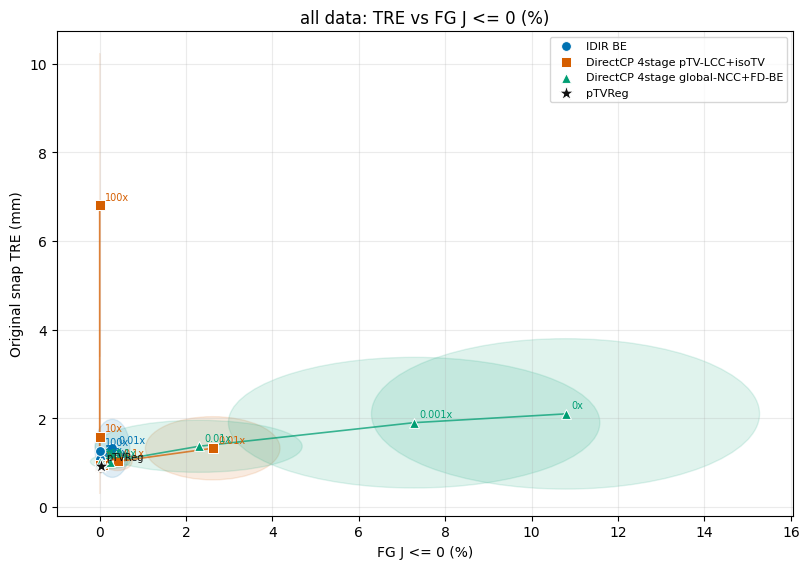

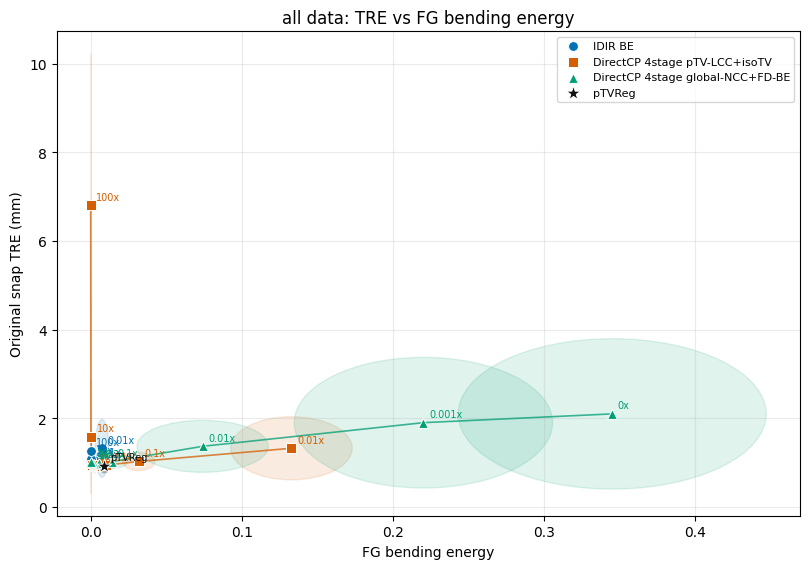

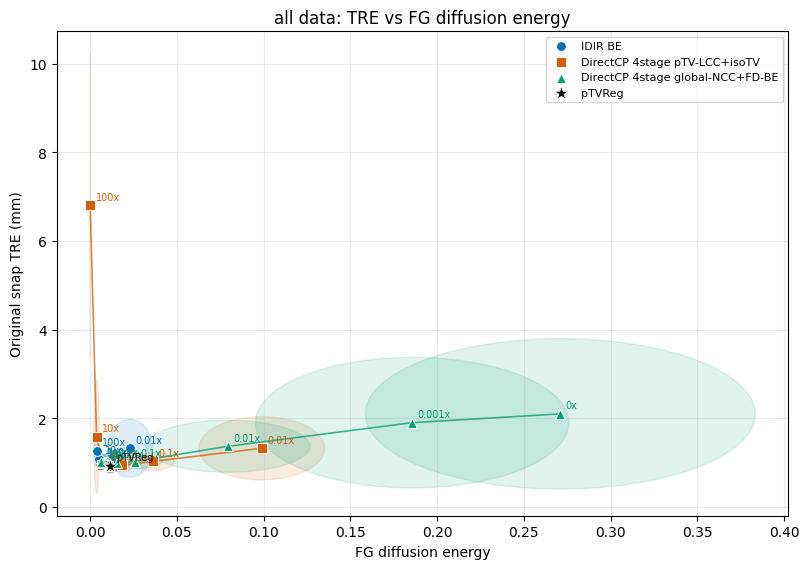

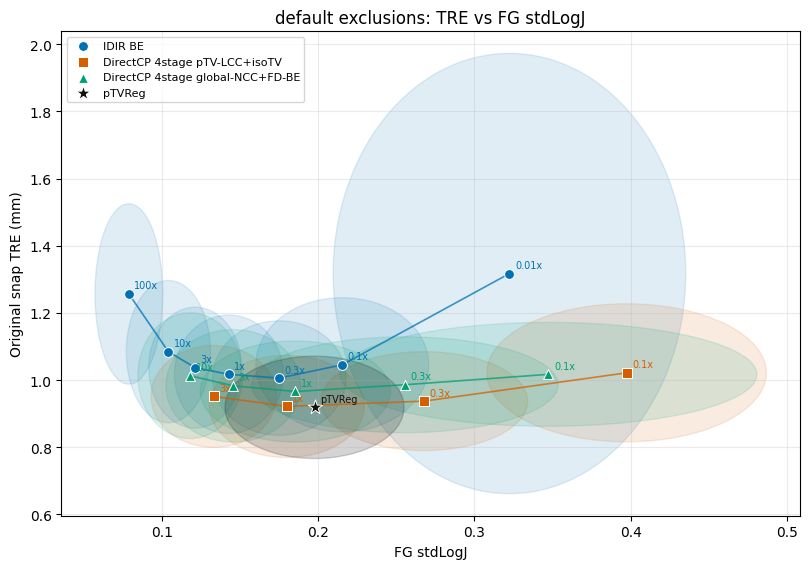

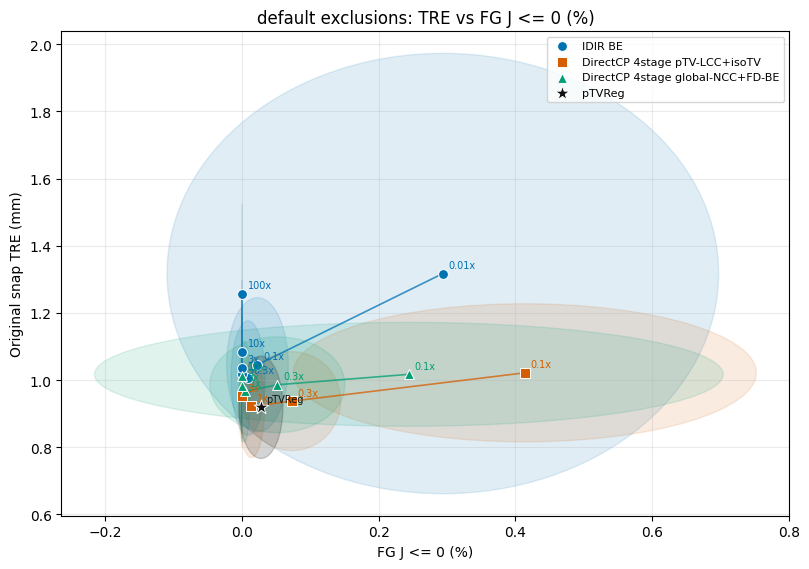

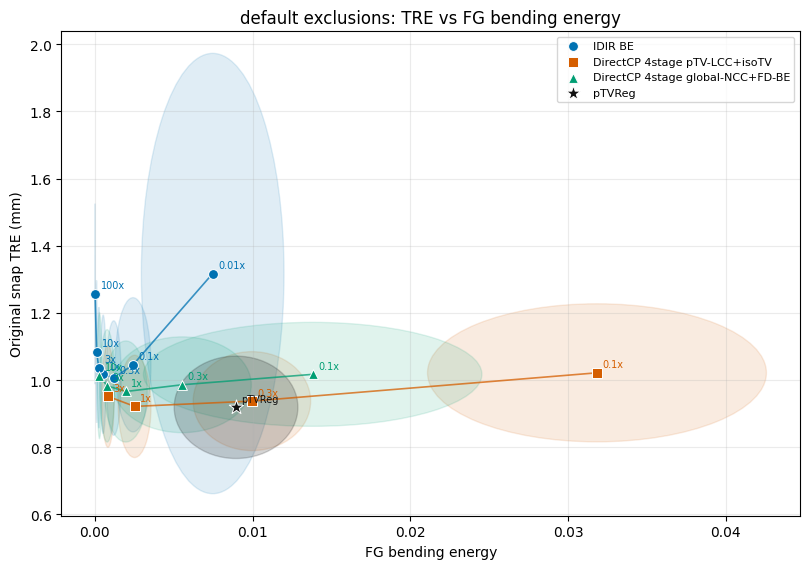

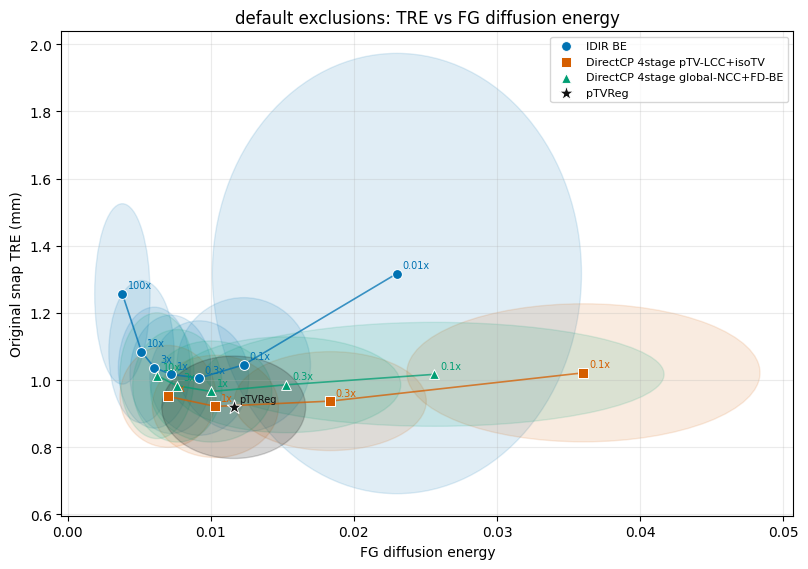

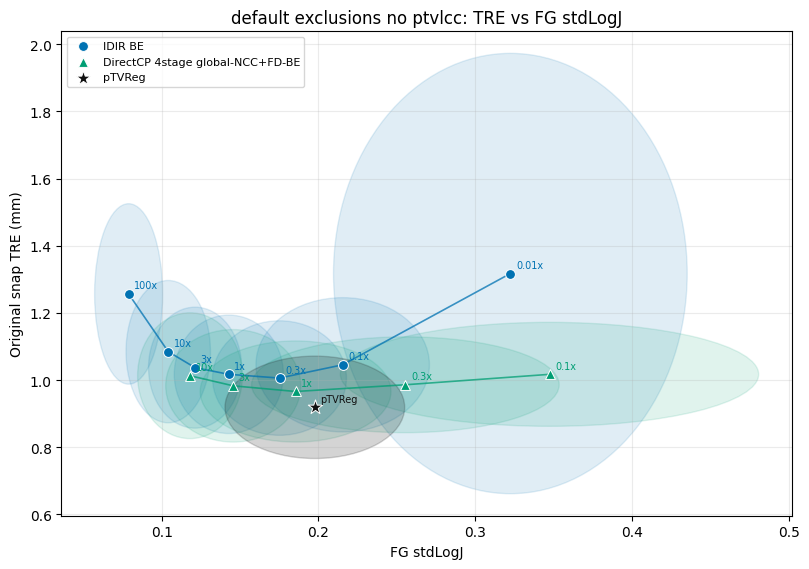

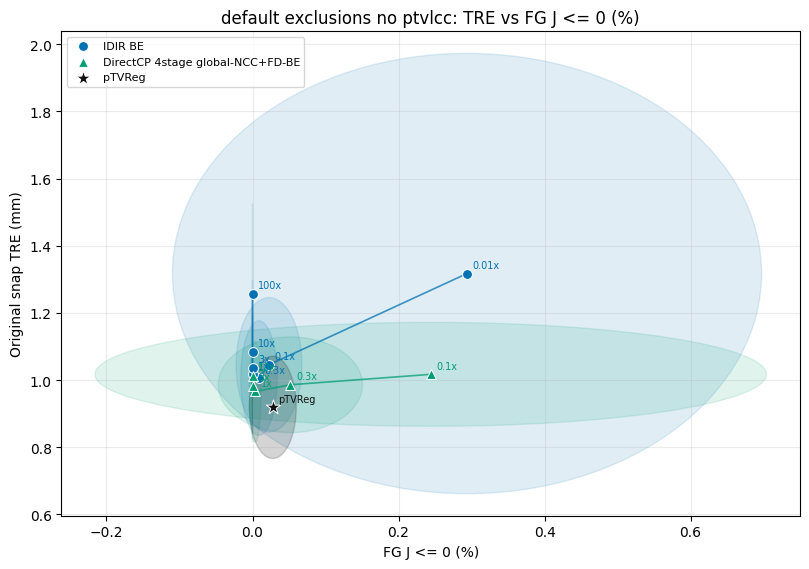

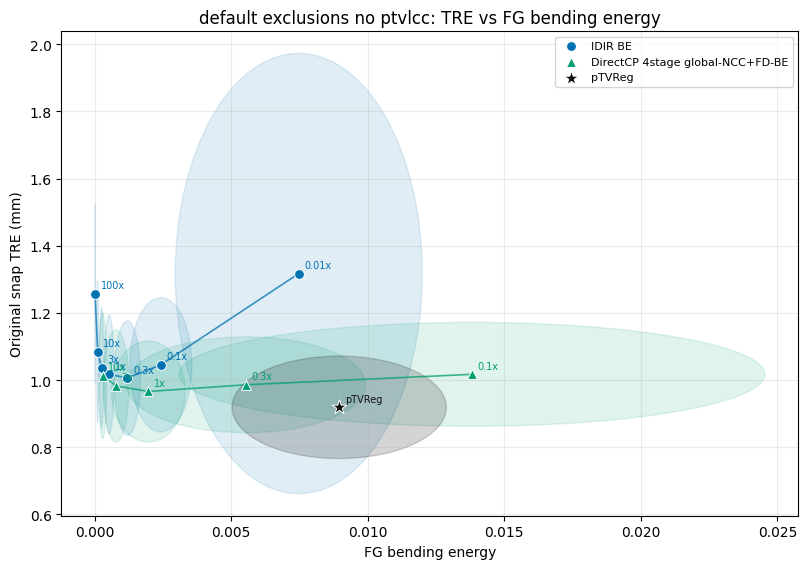

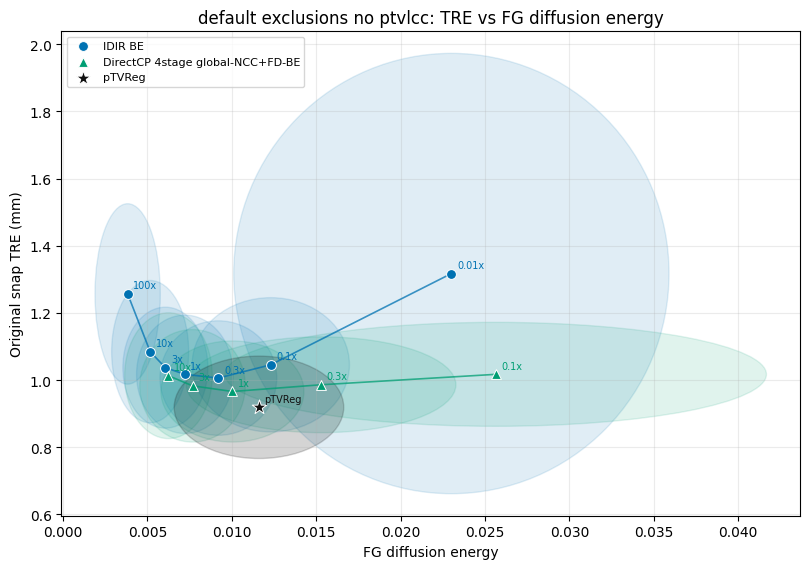

Saved artifacts:
  case_rows: /homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/combined_case_rows_with_ptvreg.csv
  mean_rows: /homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/combined_mean_rows_with_ptvreg.csv
  screening_csv: /homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/screening_table.csv
  screening_md: /homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/screening_table.md
Output validation: {'ok': True, 'missing_or_empty': [], 'expected_count': 16}


In [4]:
result = save_and_plot_review(
    case_df,
    mean_df,
    table_df,
    output_root=OUTPUT_ROOT,
    exclude_by_ratio=EXCLUDE_BY_RATIO,
    exclude_by_weight=EXCLUDE_BY_WEIGHT,
)
print('Saved artifacts:')
for key, path in result['artifacts'].items():
    print(f'  {key}: {path}')
print('Output validation:', result['validation'])
if not result['validation']['ok']:
    raise RuntimeError(result['validation'])

## Saved Figure Paths

In [5]:
for subset, paths in result['plots'].items():
    print(f'[{subset}]')
    for path in paths:
        print(path)

[all_data]
/homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/plots/all_data/original_snap_tre_vs_fg_logj_std.png
/homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/plots/all_data/original_snap_tre_vs_fg_jdet_le0_pct.png
/homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/plots/all_data/original_snap_tre_vs_fg_bending_energy.png
/homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/plots/all_data/original_snap_tre_vs_fg_diffusion_l2.png
[default_exclusions]
/homebase/code_sync/inrorspline/experiments/2026-06-26_lungct_directcp4stage_midratio_pareto_extension/pareto_visual_review_midratio_extension/plots/default_exclusions/origin